# Sinusoid Superposition

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-00.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Define parameters

In [2]:
# 1. Define Parameters
k = 1
phi_val = np.pi / 3  # A particular phase value (60 degrees)

# 2. Generate Data
# Equivalent to {x, -2*Pi, 2*Pi}
x = np.linspace(-2 * np.pi, 2 * np.pi, 1000)

# Define the functions based on your Mathematica equations
# y1: Sin[k*x]
y1 = np.sin(k * x)

# y2: Sin[k*x + phi]
y2 = np.sin(k * x + phi_val)

# ysum: 2*Sin[k*x + phi/2]*Cos[phi/2]
ysum = 2 * np.sin(k * x + phi_val / 2) * np.cos(phi_val / 2)

## Plot

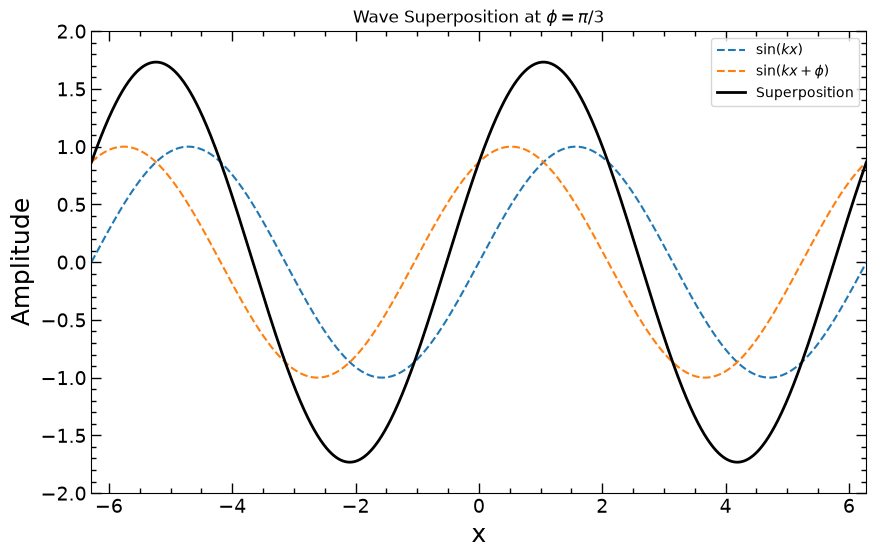

In [3]:
# 3. Create the Plot
# Creating the figure and axes variables as requested
fig1, axes1 = plt.subplots(figsize=(10, 6))

# Plotting the three lines
axes1.plot(x, y1, label=r'$\sin(kx)$', linestyle='--')
axes1.plot(x, y2, label=r'$\sin(kx + \phi)$', linestyle='--')
axes1.plot(x, ysum, label='Superposition', linewidth=2, color='black')

# 4. Formatting
# Setting the range to match PlotRange -> {All, {-2, 2}}
axes1.set_ylim(-2, 2)
axes1.set_xlim(-2 * np.pi, 2 * np.pi)

# Adding labels, title, and grid
axes1.set_title(f'Wave Superposition at $\phi = \pi/3$')
axes1.set_xlabel('x', fontsize=18)
axes1.set_ylabel('Amplitude', fontsize=18)
axes1.legend(loc='upper right')
# axes1.grid(True, alpha=0.5)
axes1.minorticks_on()
axes1.tick_params(which='both',direction="in",width=1, labelsize=14)
axes1.tick_params(which='major',length=7)
axes1.tick_params(which='minor',length=3.5)
axes1.xaxis.set_ticks_position('both')
axes1.yaxis.set_ticks_position('both')

# Show the plot
plt.show()

## Make interactive with ipywidgets

In [4]:
# Enables interactive plotting in Jupyter
%matplotlib widget 

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# 1. Define Constant Parameters
k3 = 1
x3 = np.linspace(-2 * np.pi, 2 * np.pi, 1000)
y3 = np.sin(k3 * x3)  

# 2. Create the Figure and Axes (fig2, axes2)
fig2, axes2 = plt.subplots(figsize=(9, 6))

# --- HIDE THE FIGURE HEADER/FOOTER ---
# This removes the "Figure 2" bar and the resize handle at the bottom
fig2.canvas.header_visible = False
fig2.canvas.footer_visible = False
# -------------------------------------

# 3. Initialize the Plot Lines
line1, = axes2.plot(x3, y3, label=r'$\sin(kx)$', linestyle='--', color='tab:blue')
line2, = axes2.plot(x3, np.sin(k3 * x3), label=r'$\sin(kx + \phi)$', linestyle='--', color='tab:orange')
line_sum, = axes2.plot(x3, 2 * np.sin(k3 * x3) * 1, label='Superposition', linewidth=2, color='black')

# 4. Apply Your Formatting Preferences
axes2.set_ylim(-2, 2)
axes2.set_xlim(-2 * np.pi, 2 * np.pi)
axes2.set_xlabel('x', fontsize=18)
axes2.set_ylabel('Amplitude', fontsize=18)
axes2.legend(loc='upper right')

# Specific tick formatting
axes2.minorticks_on()
axes2.tick_params(which='both', direction="in", width=1, labelsize=14)
axes2.tick_params(which='major', length=7)
axes2.tick_params(which='minor', length=3.5)
axes2.xaxis.set_ticks_position('both')
axes2.yaxis.set_ticks_position('both')

# 5. Define the Update Function
def update_plot(phi):
    # Calculate new data
    y2_new = np.sin(k3 * x3 + phi)
    ysum_new = 2 * np.sin(k3 * x3 + phi / 2) * np.cos(phi / 2)
    
    # Update the existing lines
    line2.set_ydata(y2_new)
    line_sum.set_ydata(ysum_new)
    
    # Update title
    axes2.set_title(fr'Wave Superposition ($\phi = {phi:.2f}$ rad)', fontsize=14)
    
    # Redraw fig2
    fig2.canvas.draw_idle()

# 6. Create the Slider
# Changed description to use Unicode 'φ' instead of LaTeX '$'
slider = widgets.FloatSlider(
    value=0,
    min=0,
    max=2 * np.pi,
    step=0.05,
    description='Phase φ', 
    continuous_update=True
)

# Link the slider to the update function
slider.observe(lambda change: update_plot(change['new']), names='value')

# Display the slider
display(slider)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-00_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-00.html) (direct link: [ch04-00_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-00_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.